# TP1 : Moteur de recherche d'images par le contenu (CBIR)
## Approche classique - Descripteurs globaux

**Réalisé par :** Melki Meriem
**Classe :** RT5 - Groupe 2

L'objectif est de construire un système CBIR simple. Chaque image de la base est représentée par un vecteur descripteur (index). La recherche consiste à calculer le descripteur de l'image requête puis à le comparer avec ceux de la base. Le système a donc deux phases :

- **Indexation (hors ligne)** : calcul et stockage des descripteurs de toutes les images.
- **Recherche (en ligne)** : calcul du descripteur de la requête et recherche des images dont la distance est minimale.

Base utilisée : extrait de la base COREL (dossier `obj_decoys`, 270 images de deux groupes) et deux images requêtes (dossier `img_requetes`).

## Importation des bibliothèques et chemins

In [9]:
import os
import glob
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops, hog

In [10]:
# Sur Kaggle la base est dans /kaggle/input/<nom_du_dataset>/...
# on cherche directement les deux dossiers obj_decoys et img_requetes
EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp')

def lister_images(dossier):
    return sorted([f for f in os.listdir(dossier) if f.lower().endswith(EXTENSIONS)])

def chercher_dossier(nom):
    for d in glob.glob('/kaggle/input/**/' + nom, recursive=True):
        if os.path.isdir(d) and len(lister_images(d)) > 0:
            return d
    raise FileNotFoundError("Dossier introuvable : " + nom)

dossier_base = chercher_dossier('obj_decoys')
dossier_req = chercher_dossier('img_requetes')
print("Base :", dossier_base)
print("Requetes :", dossier_req)

Base : /kaggle/input/datasets/meriemmelki/cbir-dataset/CBIR_DataSet/obj_decoys
Requetes : /kaggle/input/datasets/meriemmelki/cbir-dataset/CBIR_DataSet/img_requetes


## 3.1 Lecture des images
Lecture de toutes les images de la base et des deux images requêtes.

In [11]:
def lire_image(chemin):
    img = cv2.imread(chemin)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV lit en BGR

noms_images = lister_images(dossier_base)
base = {nom: lire_image(os.path.join(dossier_base, nom)) for nom in noms_images}
print("Nombre d'images dans la base :", len(base))

noms_req = lister_images(dossier_req)
requetes = [lire_image(os.path.join(dossier_req, nom)) for nom in noms_req]
print("Images requetes :", noms_req)

Nombre d'images dans la base : 270
Images requetes : ['ImageRequete.jpg', 'ImageRequete2.jpg']


Affichage de 6 images choisies aléatoirement dans la base :

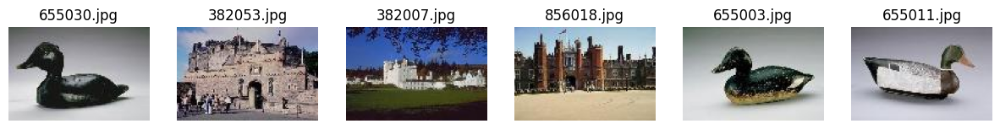

In [12]:
choix = random.sample(noms_images, 6)
plt.figure(figsize=(15, 3))
for i, nom in enumerate(choix):
    plt.subplot(1, 6, i + 1)
    plt.imshow(base[nom])
    plt.title(nom)
    plt.axis('off')
plt.show()

Affichage des images requêtes :

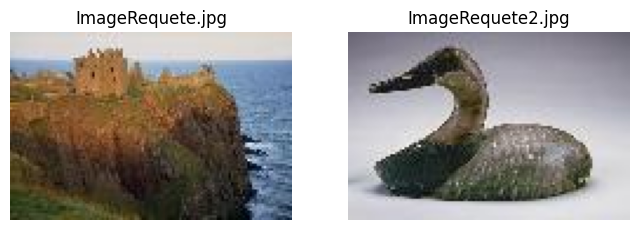

In [13]:
plt.figure(figsize=(8, 3))
for i, img in enumerate(requetes):
    plt.subplot(1, len(requetes), i + 1)
    plt.imshow(img)
    plt.title(noms_req[i])
    plt.axis('off')
plt.show()

Fonction utilisée pour afficher la requête et les 5 images les plus proches :

In [14]:
def afficher_resultats(img_req, resultats, titre=""):
    # affiche l'image requete puis les images trouvees avec leur distance
    n = len(resultats)
    plt.figure(figsize=(3 * (n + 1), 3))
    plt.subplot(1, n + 1, 1)
    plt.imshow(img_req)
    plt.title("Requete")
    plt.axis('off')
    for i, (nom, d) in enumerate(resultats):
        plt.subplot(1, n + 1, i + 2)
        plt.imshow(base[nom])
        plt.title(f"{nom}\nd = {d:.3f}", fontsize=9)
        plt.axis('off')
    plt.suptitle(titre)
    plt.tight_layout()
    plt.show()

## 3.2 Recherche par image entière
On compare directement les pixels de la requête avec ceux de chaque image de la base avec la distance euclidienne. Les images de COREL n'ont pas toutes la même orientation (384x256 ou 256x384), donc on les redimensionne à une taille commune avant le calcul. Les distances sont stockées dans un dictionnaire puis triées par ordre croissant.

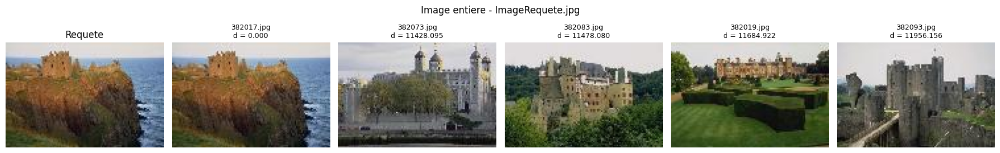

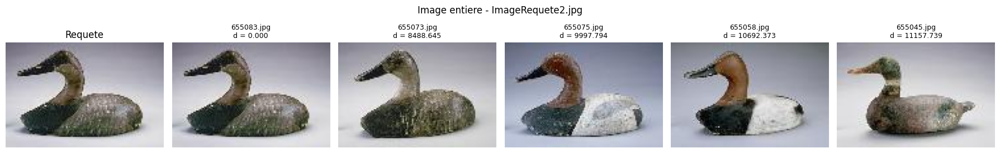

In [15]:
TAILLE = (128, 128)

def distance_euclidienne(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return np.sqrt(np.sum((a - b) ** 2))

def recherche_image_entiere(img_req, nb=5):
    req = cv2.resize(img_req, TAILLE)
    distances = {}
    for nom, img in base.items():
        distances[nom] = distance_euclidienne(req, cv2.resize(img, TAILLE))
    distances = sorted(distances.items(), key=lambda x: x[1])
    return distances[:nb]

for i, img in enumerate(requetes):
    res = recherche_image_entiere(img)
    afficher_resultats(img, res, "Image entiere - " + noms_req[i])

**Interprétation :**
La base contient deux groupes : des châteaux (images 382xxx, 612xxx, 856xxx) et des canards en bois (images 655xxx). La première image trouvée est la requête elle-même (d = 0), ce qui montre que les images requêtes font partie de la base.

Pour les deux requêtes, les 5 images trouvées sont du bon groupe. Pour le canard cela marche bien car toutes les photos de canards ont le même fond gris et la même position. Par contre cette méthode est lente (49152 valeurs par image) et dépend de la position exacte des pixels : un simple décalage de l'objet changerait beaucoup la distance.

## 3.3 Recherche par couleur (moments de couleur)
Le descripteur couleur contient la moyenne et la variance de chaque composante R, G, B, donc un vecteur de taille 6.

- `color_Moments` : calcule les 6 moments.
- `getFeatures` : construit le vecteur descripteur (c'est elle qu'on modifiera pour ajouter les autres descripteurs).
- `CBIR_Indexation` : calcule la matrice des descripteurs de toute la base (exécutée une seule fois).
- `CBIR_Recherche` : calcule le descripteur de la requête et retourne les images les plus proches.

Les composantes du vecteur n'ont pas la même échelle (la variance est beaucoup plus grande que la moyenne). Avant de calculer la distance euclidienne, on centre et on réduit chaque composante en utilisant la moyenne et l'écart type calculés sur la base d'index.

In [16]:
def color_Moments(img):
    img = img.astype(float)
    features = []
    for k in range(3):
        canal = img[:, :, k]
        features.append(np.mean(canal))
        features.append(np.var(canal))
    return np.array(features)

def getFeatures(img, fsize):
    return color_Moments(img)

def CBIR_Indexation(fsize):
    ind_Matrix = np.zeros((len(noms_images), fsize))
    for i, nom in enumerate(noms_images):
        ind_Matrix[i, :] = getFeatures(base[nom], fsize)
    return ind_Matrix, noms_images

def CBIR_Recherche(Imreq, ind_Matrix, noms, nb=5):
    f_req = getFeatures(Imreq, ind_Matrix.shape[1])
    # normalisation des composantes
    moy = ind_Matrix.mean(axis=0)
    ecart = ind_Matrix.std(axis=0) + 1e-10
    M = (ind_Matrix - moy) / ecart
    q = (f_req - moy) / ecart
    distances = {}
    for i in range(len(noms)):
        distances[noms[i]] = distance_euclidienne(q, M[i])
    distances = sorted(distances.items(), key=lambda x: x[1])
    return distances[:nb]

In [17]:
# Indexation (une seule fois)
fsize = 6
ind_Matrix, noms = CBIR_Indexation(fsize)
print("Taille de la base d'index :", ind_Matrix.shape)

Taille de la base d'index : (270, 6)


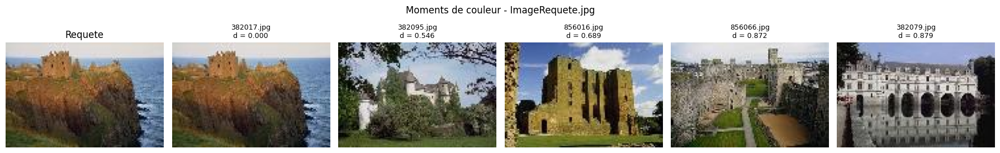

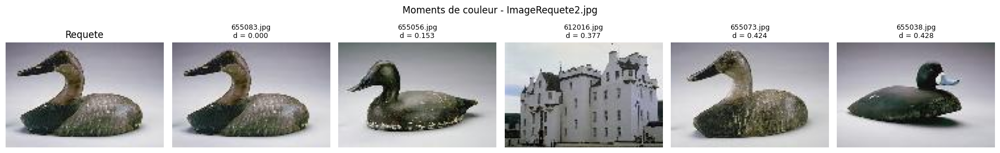

In [18]:
# Recherche
res_couleur = []
for i, img in enumerate(requetes):
    res = CBIR_Recherche(img, ind_Matrix, noms)
    res_couleur.append(res)
    afficher_resultats(img, res, "Moments de couleur - " + noms_req[i])

**Interprétation :**
Avec seulement 6 valeurs, on retrouve des images proches en couleur. Pour la requête 1, les 5 images sont des châteaux. Pour la requête 2, on a 4 canards sur 5 mais aussi un château blanc (612016.jpg) en 3e position : ses couleurs grises et blanches ressemblent au fond du canard. Les moments de couleur sont rapides mais peu discriminants car ils ne gardent aucune information sur la forme ni la répartition des couleurs.

## 3.4 Recherche par histogramme
L'histogramme est calculé dans l'espace HSV, plus proche de la perception humaine. Pour réduire la taille, on quantifie chaque composante : 8 intervalles pour la teinte H, 4 pour la saturation S et 4 pour la valeur V, ce qui donne un histogramme de 8x4x4 = 128 cases. L'histogramme est normalisé (somme = 1) pour ne pas dépendre de la taille de l'image.

Le nouveau vecteur = moments de couleur (6) + histogramme HSV (128) = 134 valeurs.

In [19]:
def hsvHistogramFeatures(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)   # H dans [0,180], S et V dans [0,256]
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256])
    hist = hist.flatten()
    return hist / hist.sum()

def getFeatures(img, fsize):
    return np.concatenate([color_Moments(img), hsvHistogramFeatures(img)])

fsize = 6 + 128
ind_Matrix, noms = CBIR_Indexation(fsize)
print("Taille de la base d'index :", ind_Matrix.shape)

Taille de la base d'index : (270, 134)


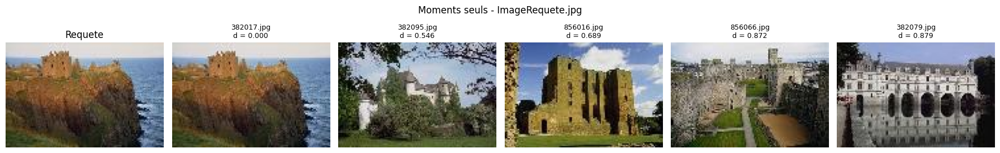

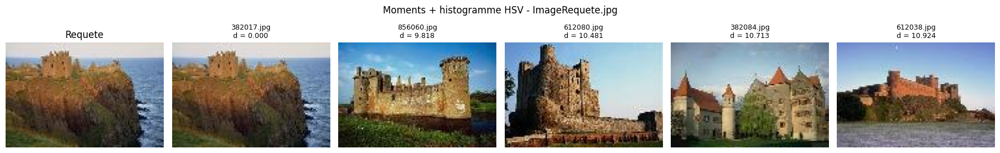

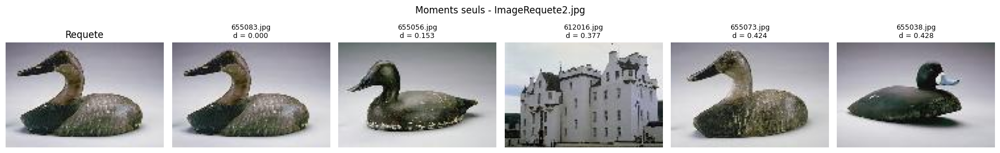

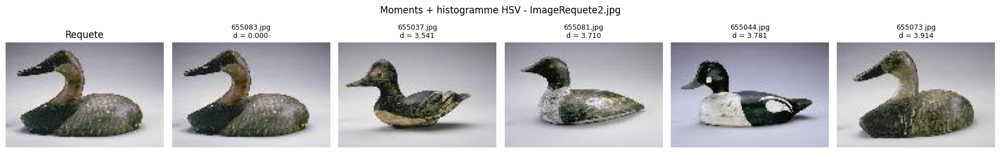

In [20]:
res_hist = []
for i, img in enumerate(requetes):
    res = CBIR_Recherche(img, ind_Matrix, noms)
    res_hist.append(res)
    afficher_resultats(img, res_couleur[i], "Moments seuls - " + noms_req[i])
    afficher_resultats(img, res, "Moments + histogramme HSV - " + noms_req[i])

**Interprétation :**
L'ajout de l'histogramme HSV améliore les résultats. Pour la requête 2, le château blanc disparaît et les 5 images sont des canards. Pour la requête 1, les châteaux trouvés ont des couleurs plus proches de la requête (pierres orangées, ciel bleu, par exemple 612038.jpg qui est aussi un château sur une colline). L'histogramme décrit toute la distribution des couleurs et pas seulement la moyenne.

## 3.5 Recherche par texture (GLCM)
Le descripteur de texture est extrait de la matrice de cooccurrence des niveaux de gris (GLCM). Comme vu en cours, on réduit d'abord le nombre de niveaux de gris (256 vers 32) pour avoir une matrice plus petite et moins sensible au bruit. La matrice est calculée pour une distance d = 1 et les 4 directions 0°, 45°, 90° et 135°. On extrait le contraste, la corrélation, l'énergie et l'homogénéité, puis on fait la moyenne sur les 4 directions : vecteur de taille 4.

Nouveau vecteur = moments (6) + histogramme (128) + texture (4) = 138 valeurs.

In [21]:
def textureFeatures(img):
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = (gris // 8).astype(np.uint8)    # 32 niveaux de gris
    glcm = graycomatrix(gris, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    proprietes = ['contrast', 'correlation', 'energy', 'homogeneity']
    return np.array([graycoprops(glcm, p).mean() for p in proprietes])

def getFeatures(img, fsize):
    return np.concatenate([color_Moments(img), hsvHistogramFeatures(img), textureFeatures(img)])

fsize = 6 + 128 + 4
ind_Matrix, noms = CBIR_Indexation(fsize)
print("Taille de la base d'index :", ind_Matrix.shape)

Taille de la base d'index : (270, 138)


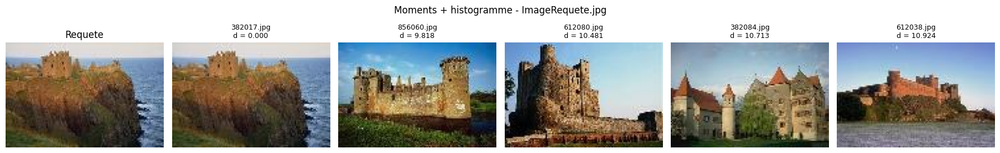

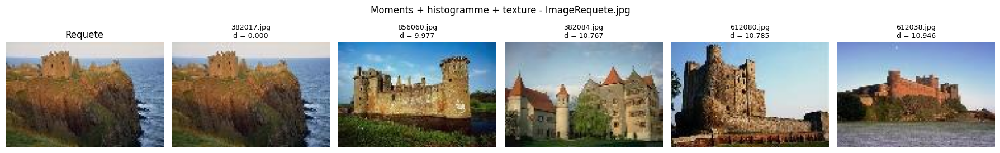

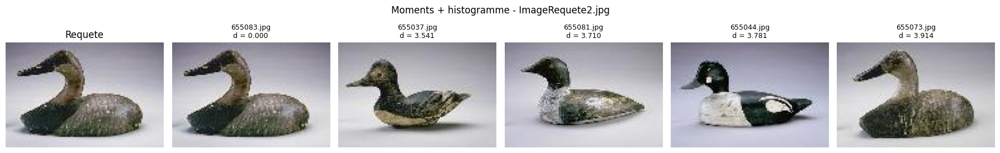

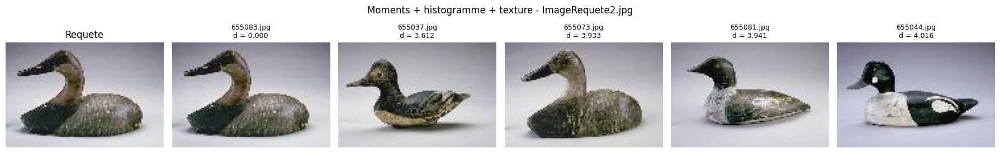

In [22]:
res_texture = []
for i, img in enumerate(requetes):
    res = CBIR_Recherche(img, ind_Matrix, noms)
    res_texture.append(res)
    afficher_resultats(img, res_hist[i], "Moments + histogramme - " + noms_req[i])
    afficher_resultats(img, res, "Moments + histogramme + texture - " + noms_req[i])

**Interprétation :**
Les résultats changent très peu : on retrouve presque les mêmes images, seul l'ordre change (par exemple 655073.jpg monte en 3e position pour la requête 2). C'est normal car la texture n'a que 4 valeurs contre 134 pour la couleur, son poids dans la distance est faible.

## 3.6 Recherche par forme (HOG)
Le descripteur HOG (histogramme des orientations du gradient) décrit la forme des objets à partir des contours. Étapes :
- conversion en niveaux de gris et redimensionnement à 64x64 (pour avoir un vecteur de même taille pour toutes les images),
- découpage en cellules de 8x8 pixels,
- histogramme de 8 orientations par cellule,
- normalisation par blocs de 2x2 cellules,
- concaténation de tous les histogrammes.

On obtient 7 x 7 blocs x 4 cellules x 8 orientations = 1568 valeurs.

In [23]:
def shapeFeaturesHOG(img):
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    gris = cv2.resize(gris, (64, 64))
    return hog(gris, orientations=8, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm='L2-Hys')

print("Taille du vecteur HOG :", len(shapeFeaturesHOG(requetes[0])))

def getFeatures(img, fsize):
    return np.concatenate([color_Moments(img), hsvHistogramFeatures(img),
                           textureFeatures(img), shapeFeaturesHOG(img)])

fsize = 6 + 128 + 4 + 1568
ind_Matrix, noms = CBIR_Indexation(fsize)
print("Taille de la base d'index :", ind_Matrix.shape)

Taille du vecteur HOG : 1568
Taille de la base d'index : (270, 1706)


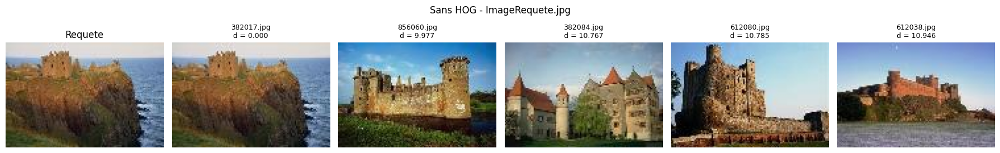

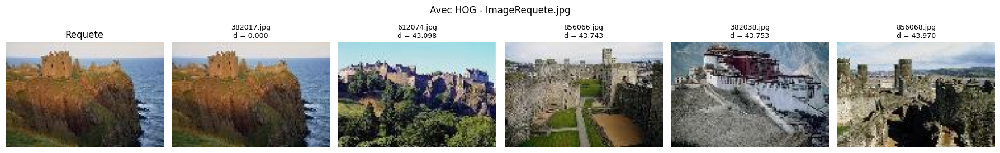

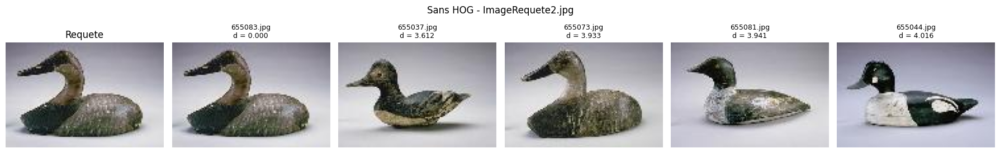

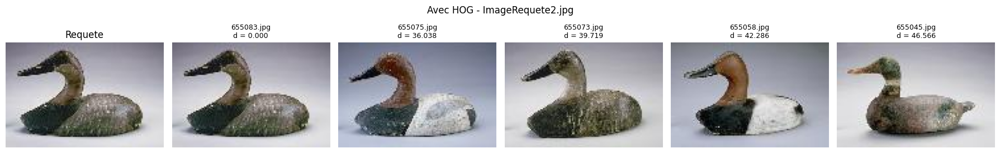

In [24]:
# comparaison sans et avec HOG pour les deux images requetes
for i, img in enumerate(requetes):
    res = CBIR_Recherche(img, ind_Matrix, noms)
    afficher_resultats(img, res_texture[i], "Sans HOG - " + noms_req[i])
    afficher_resultats(img, res, "Avec HOG - " + noms_req[i])

**Interprétation :**
Avec le HOG, les résultats changent complètement. Pour la requête 2, on retrouve des canards qui ont la même silhouette et la même orientation (tête à gauche), même si leurs couleurs sont différentes (655075.jpg et 655058.jpg ont une tête rousse et un corps blanc). Pour la requête 1, on obtient des châteaux en ruines ou sur une pente, avec une structure proche mais des couleurs différentes.

On remarque que le HOG (1568 valeurs) domine le vecteur : les résultats sont presque les mêmes qu'avec le HOG seul, la couleur et la texture ne comptent presque plus.

## 3.7 Robustesse vis-à-vis des transformations géométriques
On applique aux images requêtes une translation, une rotation et un changement d'échelle, puis on relance la recherche avec le descripteur complet (couleur + histogramme + texture + HOG).

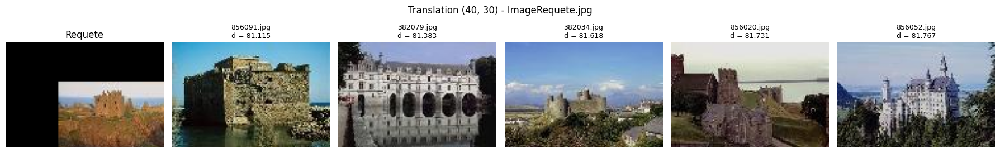

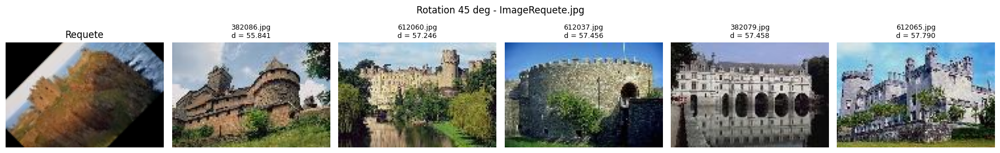

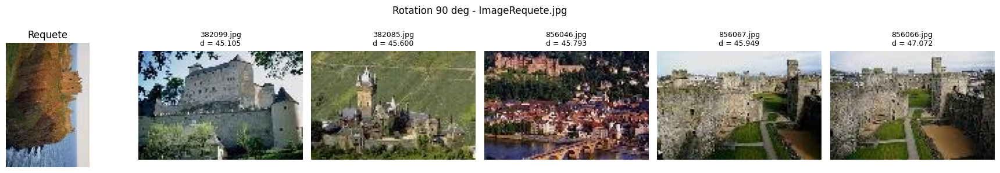

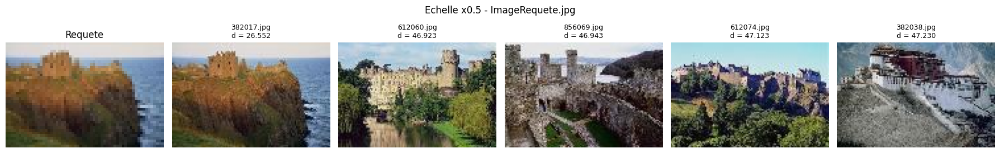

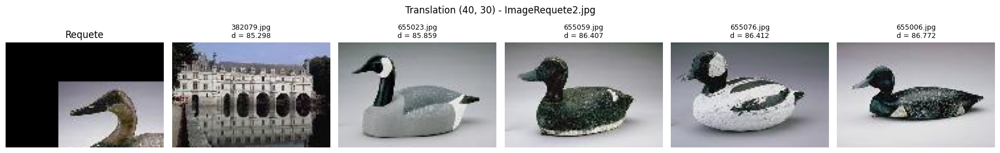

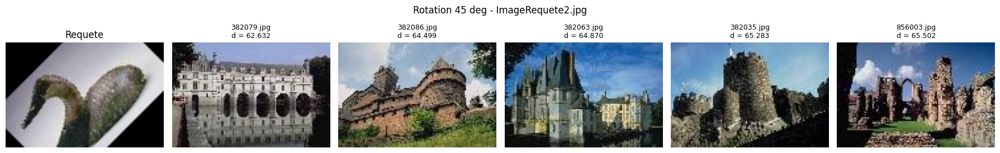

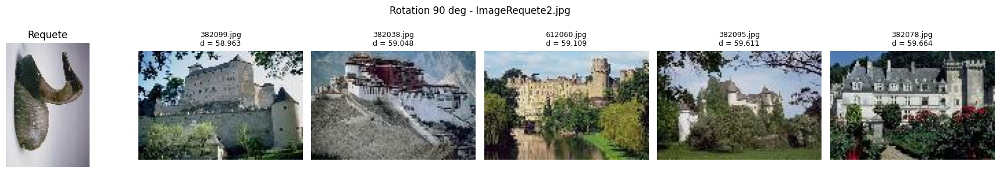

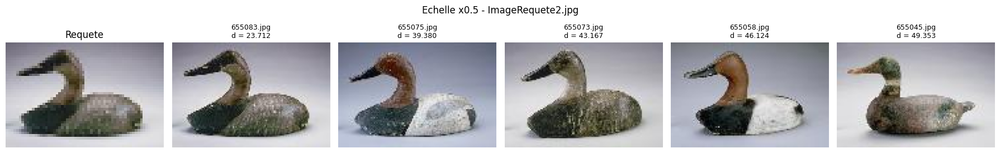

In [25]:
def translation(img, tx, ty):
    h, w = img.shape[:2]
    M = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(img, M, (w, h))

def rotation(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1)
    return cv2.warpAffine(img, M, (w, h))

def changement_echelle(img, facteur):
    return cv2.resize(img, None, fx=facteur, fy=facteur)

for i, img in enumerate(requetes):
    transformations = {
        "Translation (40, 30)": translation(img, 40, 30),
        "Rotation 45 deg": rotation(img, 45),
        "Rotation 90 deg": cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE),
        "Echelle x0.5": changement_echelle(img, 0.5),
    }
    for nom_t, img_t in transformations.items():
        res = CBIR_Recherche(img_t, ind_Matrix, noms)
        afficher_resultats(img_t, res, nom_t + " - " + noms_req[i])

**Interprétation :**
- **Changement d'échelle** : très robuste. Pour les deux requêtes, l'image d'origine est retrouvée en 1re position et les résultats sont les mêmes qu'avant.
- **Translation** : les résultats se dégradent. L'image d'origine n'est plus retrouvée, et pour la requête 2 un château apparaît en 1re position. La bande noire ajoutée change les couleurs et la position des contours.
- **Rotation** : c'est le pire cas. Pour la requête 2 (45° et 90°), les 5 images sont des châteaux, aucun canard. Pour la requête 1, on obtient encore des châteaux mais l'image d'origine n'est plus retrouvée. Le HOG, qui domine le vecteur, n'est pas invariant à la rotation.

Notre système est donc robuste au changement d'échelle mais pas à la translation ni à la rotation, principalement à cause du HOG.